In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import imblearn

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

In [2]:
df = pd.read_csv("../Sonar.csv")

In [3]:
df.head()

,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar52,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,Material
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0141,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,R
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0153,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,M
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0131,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,M
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0339,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,M
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0222,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,M


In [21]:
df.head()

,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,M,R
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,0,1
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,1,0
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,1,0
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,1,0
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,1,0


In [5]:
DummyStuff = pd.get_dummies(df["Material"], dtype=int)
df = df.drop("Material", axis=1)

df = pd.concat([df, DummyStuff], axis=1)

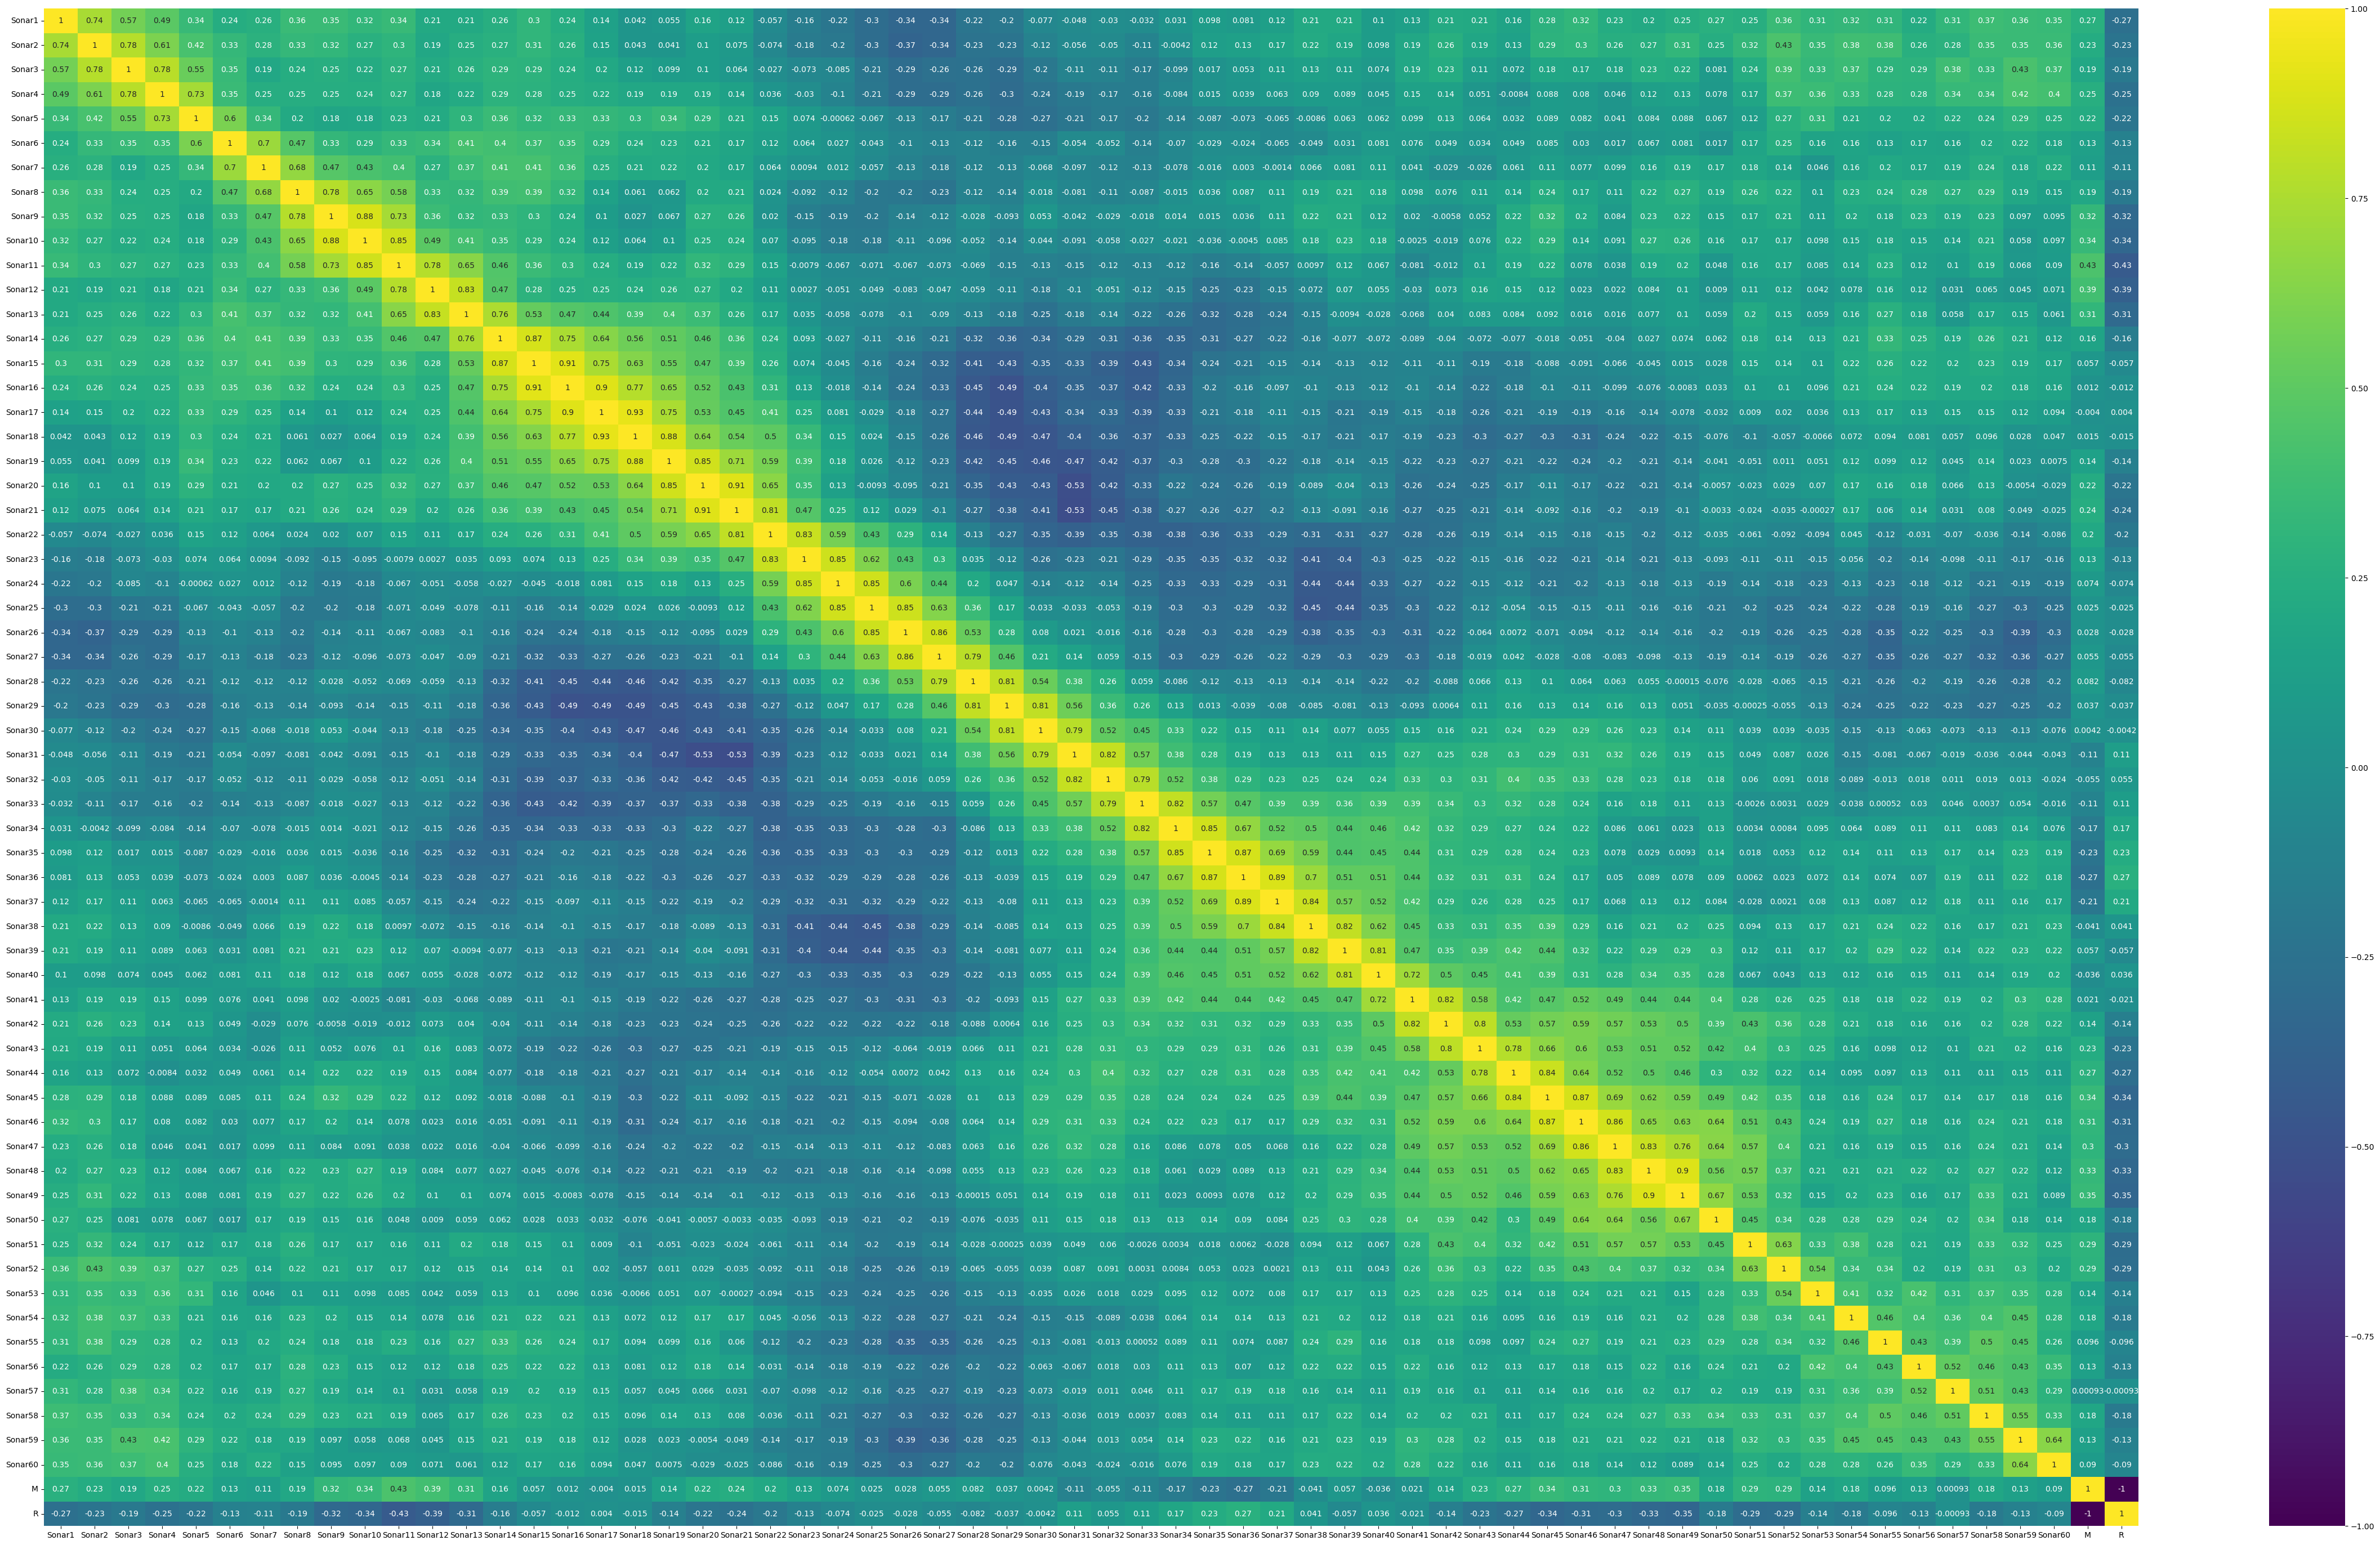

In [6]:
plt.figure(figsize=(60, 35))
sns.heatmap(df.corr(), cmap="viridis", annot=True)
plt.savefig("corr_heatmap.jpg", dpi=300, bbox_inches="tight")

In [7]:
X = df[["Sonar11", "Sonar12", "Sonar10", "Sonar9", "Sonar13", "Sonar49", "Sonar52"]]
y = df["M"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

In [8]:
model = KNeighborsClassifier(n_neighbors=9)
model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=9)

In [9]:
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.88      0.79      0.83        28
           1       0.78      0.88      0.82        24

    accuracy                           0.83        52
   macro avg       0.83      0.83      0.83        52
weighted avg       0.83      0.83      0.83        52



In [35]:
Rockies = 0
Mine_ies = 0

for i in predictions:
    if int(i) == 1:
        Mine_ies += 1
    else:
        Rockies += 1

print("ROCKS:", Rockies)
print("MINES:", Mine_ies)

ROCKS: 25
MINES: 27


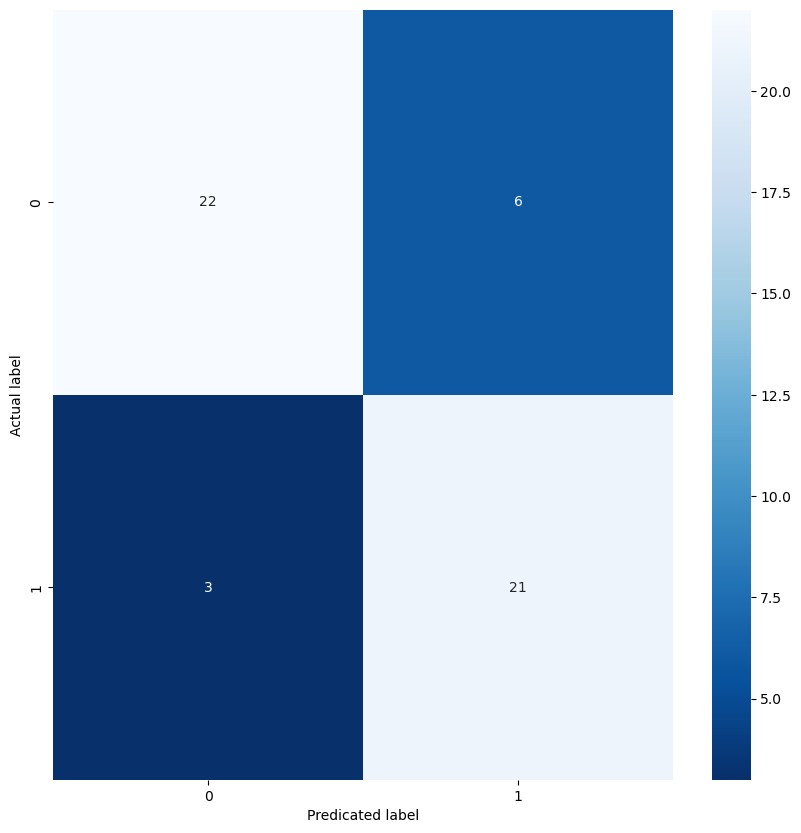

In [12]:
cm = metrics.confusion_matrix(y_test, predictions)
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, cmap="Blues_r")
plt.ylabel("Actual label")
plt.xlabel("Predicated label")
plt.show()

In [13]:
accuracy_score(predictions, y_test)

0.8269230769230769

In [14]:
precision_score(predictions, y_test)

0.875

In [15]:
recall_score(predictions, y_test)

0.7777777777777778

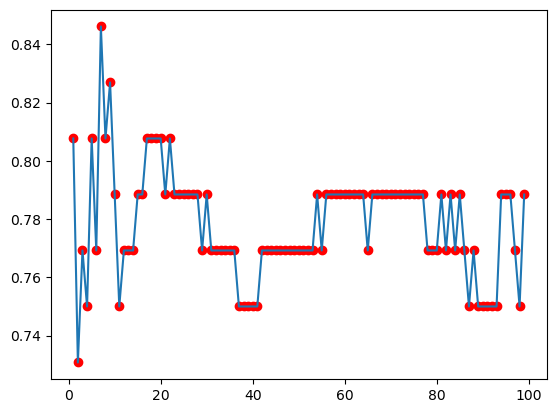

In [21]:
iarray = []
values = []

for i in range (1, 100):
    iarray.append(i)
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    values.append(accuracy_score(y_test, predictions))

plt.plot(iarray, values)
plt.scatter(iarray, values, color="red")

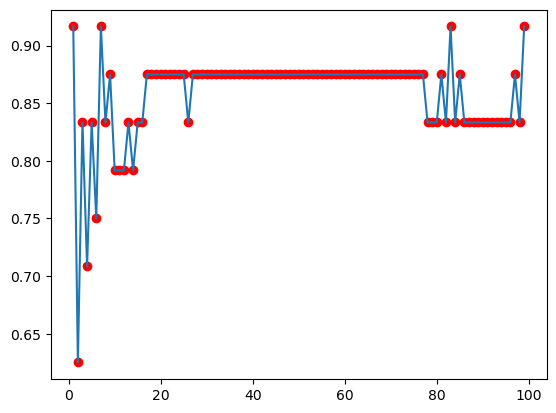

In [22]:
iarray = []
values = []

for i in range (1, 100):
    iarray.append(i)
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    values.append(recall_score(y_test, predictions))

plt.plot(iarray, values)
plt.scatter(iarray, values, color="red")